# Exploratory Data Analysis

## Overview :-

**What this notebook does :**
- explores the weekly sales of the 100 selected products before building any model
- looks at each column alone, then at how sales change with time, category, events, SNAP days and price
- writes down what the findings mean for the models

**Approach followed :**
- only the weeks up to the first forecast date are explored, the later weeks are kept unseen for testing the models
- outliers are judged inside each product (a big week for a big product is normal), not across all products together
- price is compared with sales inside each product, because prices differ a lot between products
- time series analysis : trend, seasonality, STL decomposition, ADF stationarity test, ACF and PACF

**Steps :**
- 1 . Import Required Modules
- 2 . Settings
- 3 . Data Reading
- 4 . Domain Analysis
- 5 . Basic Checks
- 6 . Exploratory Data Analysis
- 7 . Time Series Analysis

**Reads / Writes :**
- **Reads :** `data/prepared/weekly_sales.parquet`
- **Writes :** nothing, this notebook only explores the data

# 1 . Import Required Modules :-

In [1]:
## import the libraries used in this notebook
import numpy as np                          # import numpy library for numerical calculation
import pandas as pd                         # import pandas library for reading the data
import matplotlib.pyplot as plt             # import matplotlib library for plotting graphs
import seaborn as sns                       # import seaborn library for data visualisation
%matplotlib inline

import warnings                             # import warnings to ignore future warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)  # show all columns of a table

# 2 . Settings :-

- **DATA_DIR :** folder with the prepared dataset from the data preparation notebook

In [2]:
## folder of the prepared dataset
DATA_DIR = '../data/prepared/'                                            # prepared dataset folder

# 3 . Data Reading :-

The models will be tested on the weeks after the first forecast date, **18 Oct 2015** (`EDA_END`). If we explore those weeks now, what we see could shape the models, and the test would no longer be fair. So only the weeks up to that date are explored.

In [3]:
## read the prepared dataset and keep only the weeks up to the first forecast date
EDA_END = pd.Timestamp('2015-10-18')                                      # first forecast date, the EDA stops here

full_data = pd.read_parquet(DATA_DIR + 'weekly_sales.parquet')            # weekly sales of the 100 selected products
data = full_data[full_data['week'] <= EDA_END].reset_index(drop=True)     # weeks up to the first forecast date

print("Full data shape : ", full_data.shape)
print("EDA data shape  : ", data.shape)
print("Weeks           : ", data['week'].min().date(), " to ", data['week'].max().date())

Full data shape :  (17600, 11)
EDA data shape  :  (14500, 11)
Weeks           :  2013-01-13  to  2015-10-18


### Insights :-
- The EDA data has **14,500** rows : **100** products x **145** weeks, from the week ending **13 Jan 2013** to **18 Oct 2015**.
- **3,100** rows (the last **31** weeks) are not explored, because they are used later to test the models.

# 4 . Domain Analysis :-

- **item_id :** product code
- **dept_id :** department of the product, e.g. `FOODS_3`
- **cat_id :** category of the product, **FOODS** or **HOUSEHOLD**
- **first_sale_date :** first day the product ever sold
- **week :** the Sunday that ends the Monday-Sunday week
- **sales :** units sold in the week (what we forecast)
- **price :** average price of the product in the week, filled from earlier weeks when missing
- **price_missing :** 1 if the week had no price at all and was filled, else 0
- **price_missing_days :** number of days in the week without a price
- **event_days :** number of days in the week with a holiday or event
- **snap_days :** number of SNAP days in the week (food benefit purchases allowed in California)

# 5 . Basic Checks :-

In [4]:
## first rows of the data
data.head()

,item_id,dept_id,cat_id,first_sale_date,week,sales,price,price_missing,price_missing_days,event_days,snap_days
0,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-01-13,67,1.78,0,0,1,4
1,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-01-20,29,1.78,0,0,0,0
2,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-01-27,0,1.78,0,0,1,0
3,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-02-03,0,1.78,0,0,1,3
4,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-02-10,131,1.78,0,0,0,7


In [5]:
## last rows of the data
data.tail()

,item_id,dept_id,cat_id,first_sale_date,week,sales,price,price_missing,price_missing_days,event_days,snap_days
14495,HOUSEHOLD_2_176,HOUSEHOLD_2,HOUSEHOLD,2011-01-29,2015-09-20,27,4.97,0,0,0,0
14496,HOUSEHOLD_2_176,HOUSEHOLD_2,HOUSEHOLD,2011-01-29,2015-09-27,36,4.97,0,0,1,0
14497,HOUSEHOLD_2_176,HOUSEHOLD_2,HOUSEHOLD,2011-01-29,2015-10-04,26,4.97,0,0,0,4
14498,HOUSEHOLD_2_176,HOUSEHOLD_2,HOUSEHOLD,2011-01-29,2015-10-11,27,4.97,0,0,0,6
14499,HOUSEHOLD_2_176,HOUSEHOLD_2,HOUSEHOLD,2011-01-29,2015-10-18,32,4.97,0,0,1,0


In [6]:
## column types and non-empty values
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 14500 entries, 0 to 14499
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   item_id             14500 non-null  str           
 1   dept_id             14500 non-null  str           
 2   cat_id              14500 non-null  str           
 3   first_sale_date     14500 non-null  datetime64[us]
 4   week                14500 non-null  datetime64[us]
 5   sales               14500 non-null  int64         
 6   price               14310 non-null  float64       
 7   price_missing       14500 non-null  int64         
 8   price_missing_days  14500 non-null  int64         
 9   event_days          14500 non-null  int64         
 10  snap_days           14500 non-null  int64         
dtypes: datetime64[us](2), float64(1), int64(5), str(3)
memory usage: 1.6 MB


### Insights :-
- **11** columns : 3 text columns (`item_id`, `dept_id`, `cat_id`), 2 date columns (`first_sale_date`, `week`) and 6 number columns.
- All columns are complete except `price`, which has **14,310** of **14,500** values.

In [7]:
## summary of the number columns
data.describe()                             # statistical information of numerical columns

,first_sale_date,week,sales,price,price_missing,price_missing_days,event_days,snap_days
count,14500,14500,14500.000000,14310.000000,14500.000000,14500.000000,14500.000000,14500.000000
mean,2011-10-09 09:07:12,2014-06-01 00:00:00,76.344345,1.960790,0.013103,0.097931,0.558621,2.303448
min,2011-01-29 00:00:00,2013-01-13 00:00:00,0.000000,0.780000,0.000000,0.000000,0.000000,0.000000
25%,2011-01-29 00:00:00,2013-09-22 00:00:00,27.000000,0.980000,0.000000,0.000000,0.000000,0.000000
50%,2011-01-30 00:00:00,2014-06-01 00:00:00,51.000000,1.580000,0.000000,0.000000,0.000000,1.000000
75%,2012-06-10 00:00:00,2015-02-08 00:00:00,96.000000,2.500000,0.000000,0.000000,1.000000,5.000000
max,2013-10-14 00:00:00,2015-10-18 00:00:00,1697.000000,7.970000,1.000000,7.000000,3.000000,7.000000
std,NaN,NaN,87.060380,1.287281,0.113722,0.814591,0.663097,2.668746


### Insights :-
- Average weekly sales are **76.3** units, but the median is only **51**, so a few big weeks pull the average up.
- Half of the product-weeks sell between **27** and **96** units, and the biggest week sold **1,697** units.
- Prices are low, from **0.78** to **7.97**, with a median of **1.58**.
- Only **1.3 %** of the weeks had no price at all and were filled from earlier weeks (`price_missing` mean **0.013**).
- Half of the products first sold in the first two days of the data (**29-30 Jan 2011**), and the newest one first sold on **14 Oct 2013**.

In [8]:
## summary of the text columns
data.describe(include='object')             # statistical information of categorical columns

,item_id,dept_id,cat_id
count,14500,14500,14500
unique,100,5,2
top,FOODS_1_004,HOUSEHOLD_1,FOODS
freq,145,7105,7250


In [9]:
## duplicate product-weeks, weeks per product and missing values
print("Duplicate product-weeks : ", data.duplicated(['item_id', 'week']).sum())
print("Weeks per product (min / max) : ", data.groupby('item_id')['week'].nunique().min(), "/",
      data.groupby('item_id')['week'].nunique().max())
data.isnull().sum()                         # missing values in each column

Duplicate product-weeks :  0
Weeks per product (min / max) :  145 / 145


item_id                 0
dept_id                 0
cat_id                  0
first_sale_date         0
week                    0
sales                   0
price                 190
price_missing           0
price_missing_days      0
event_days              0
snap_days               0
dtype: int64

### Insights :-
- No duplicate product-weeks, and every product has all **145** weeks.
- The **190** missing prices are weeks before the product's first price, so there is no earlier price to fill them with. Sales in those weeks are still recorded.

# 6 . Exploratory Data Analysis :-

## ( i ) . Univariate Analysis :-

In [10]:
## number columns, and the category columns with one row per product
data_num = data[['sales', 'event_days', 'snap_days', 'price', 'price_missing_days']]   # numerical columns
data_cat = data.drop_duplicates('item_id')[['cat_id', 'dept_id']]                     # categorical columns (one row per product)

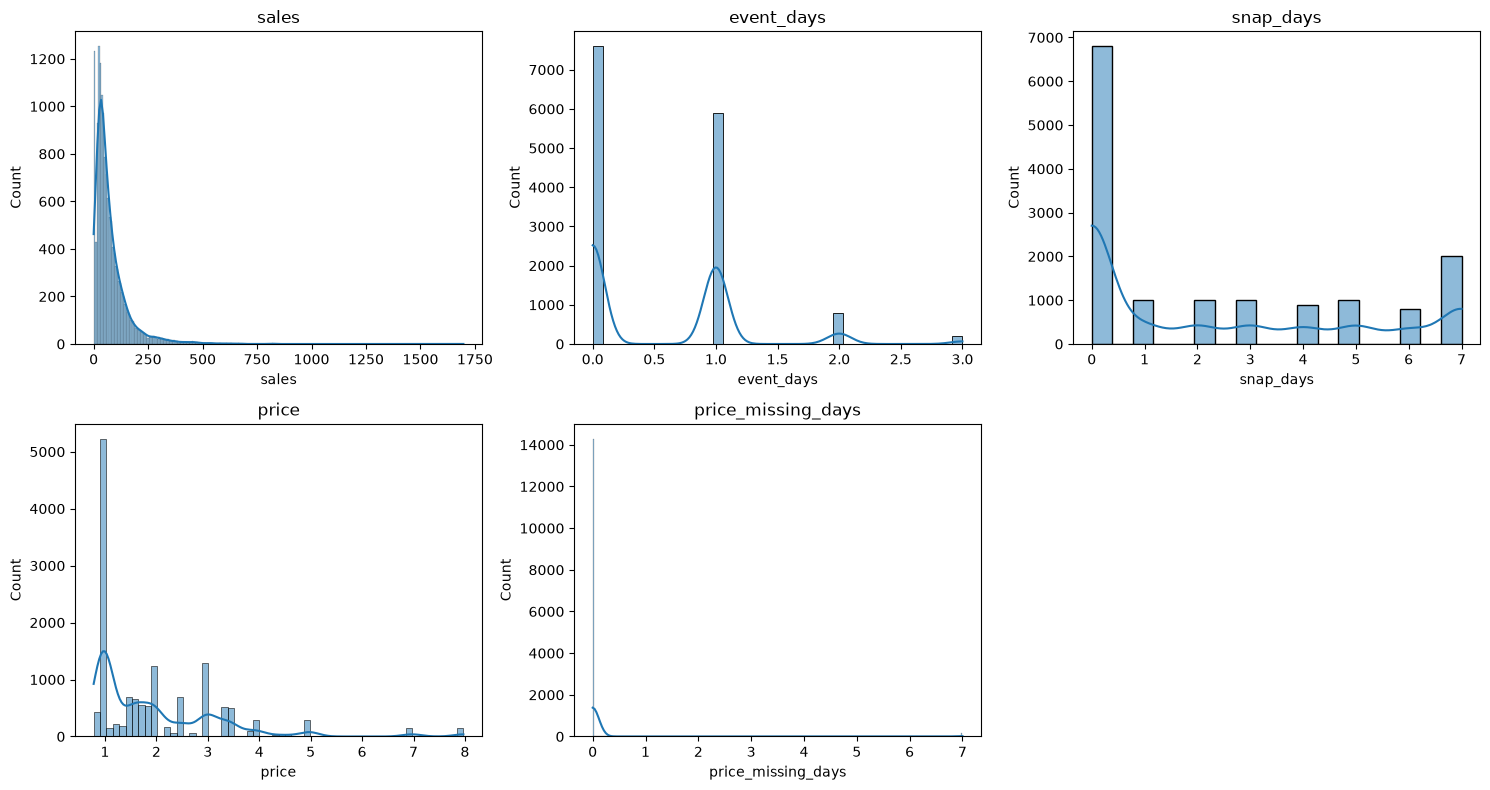

sales                 4.32
event_days            1.06
snap_days             0.68
price                 2.00
price_missing_days    8.24
dtype: float64

In [11]:
## distribution of every number column and its skewness
plt.figure(figsize=(15,8))                  # Set Canvas size
plotnumber = 1                              # Create a variable
for i in data_num:                          # loop over numerical columns
    plt.subplot(2,3,plotnumber)             # rows & columns according to no. of columns
    sns.histplot(x=data_num[i],kde=True)
    plt.title(i)
    plotnumber = plotnumber + 1
plt.tight_layout()                          # to avoid overlapping of plots
plt.show()

data_num.skew().round(2)                    # skewness of each numerical column

### Insights :-
- `sales` is strongly **right skewed** (skew **4.32**) : most weeks sell under 250 units, with a long tail up to 1,697.
- Most weeks have **0** or **1** event day, and only a few have 2 or 3.
- `snap_days` is **0** in most weeks, and the second most common value is **7** (a full SNAP week).
- Most prices are around **1**, so `price` is also right skewed (skew **2.00**).
- `price_missing_days` is almost always **0** (skew **8.24**), so price gaps are rare.

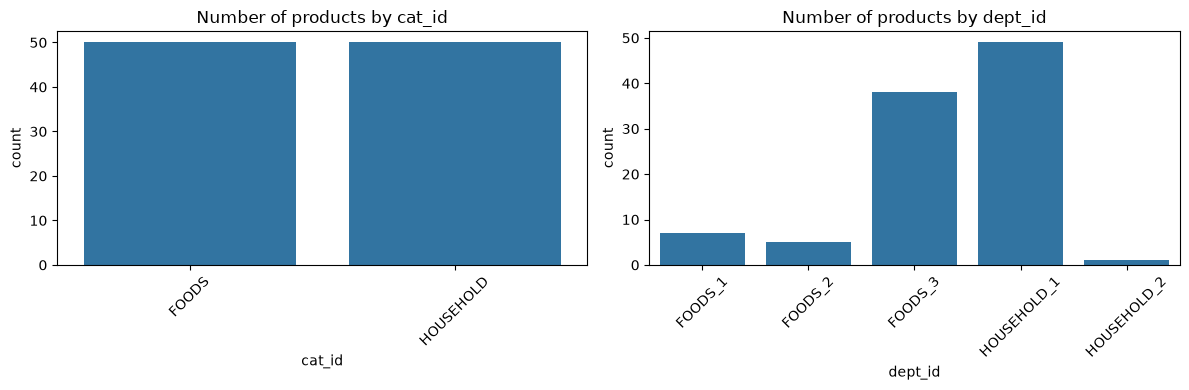

dept_id
HOUSEHOLD_1    49
FOODS_3        38
FOODS_1         7
FOODS_2         5
HOUSEHOLD_2     1
Name: count, dtype: int64

In [12]:
## number of products per category and per department
plt.figure(figsize=(12,4))                  # Set Canvas size
plotnumber = 1                              # Create a variable
for i in data_cat:                          # loop over categorical columns
    plt.subplot(1,2,plotnumber)
    sns.countplot(x=data_cat[i])
    plt.title("Number of products by " + i)
    plt.xticks(rotation=45)
    plotnumber = plotnumber + 1
plt.tight_layout()                          # to avoid overlapping of plots
plt.show()

data_cat['dept_id'].value_counts()

### Insights :-
- The 100 products come mostly from two departments : **HOUSEHOLD_1** (**49**) and **FOODS_3** (**38**).
- FOODS_1 has **7**, FOODS_2 has **5** and HOUSEHOLD_2 only **1** product, because the products were chosen by sales volume.

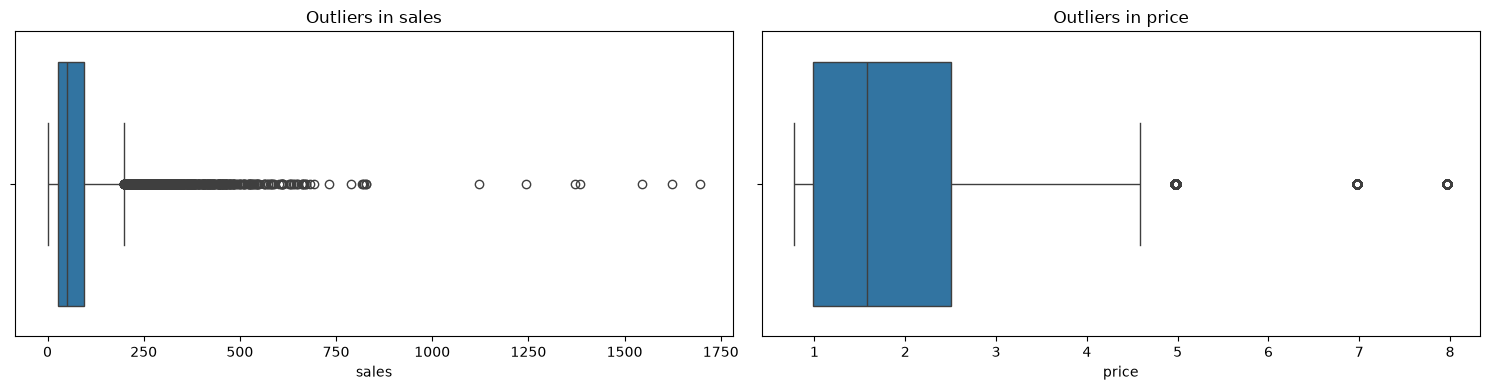

Upper limit of sales :  199.5
Product-weeks above the upper limit :  964


In [13]:
## boxplots of sales and price, and outliers by the IQR rule
plt.figure(figsize=(15,4))                  # Set Canvas size
plotnumber = 1                              # Create a variable
for i in ['sales', 'price']:                # columns to check for outliers
    plt.subplot(1,2,plotnumber)
    sns.boxplot(x=data[i])
    plt.title("Outliers in " + i)
    plotnumber = plotnumber + 1
plt.tight_layout()                          # to avoid overlapping of plots
plt.show()

## outliers by the IQR rule
q1 = data['sales'].quantile(0.25)
q3 = data['sales'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)                # upper limit
print("Upper limit of sales : ", upper)
print("Product-weeks above the upper limit : ", (data['sales'] > upper).sum())

### Insights :-
- The boxplot marks every week above **199.5** units as an outlier, which is **964** product-weeks.
- These weeks belong to the big products, so they are normal for them and are not errors. Comparing all products together is not a fair outlier check.

Sales are counted per product, so a high week for a big product is normal and not an outlier. A better check is a peak compared with the product's own average : weeks more than **4** standard deviations above the product mean.

In [14]:
## weeks far above their own product's average
data['z'] = (data['sales'] - data.groupby('item_id')['sales'].transform('mean')) / data.groupby('item_id')['sales'].transform('std')
peaks = data[data['z'] > 4].sort_values('z', ascending=False)        # weeks far above the product's own average

print("Peak weeks : ", peaks.shape[0], " out of ", data.shape[0])
peaks[['item_id', 'week', 'sales', 'z', 'event_days', 'price', 'price_missing']].head(15).round(2)

Peak weeks :  13  out of  14500


,item_id,week,sales,z,event_days,price,price_missing
7130,FOODS_3_785,2013-07-07,463,5.86,1,2.98,0
6312,FOODS_3_702,2014-07-06,455,5.11,1,2.98,0
13636,HOUSEHOLD_1_494,2013-02-24,53,5.04,3,7.97,0
356,FOODS_1_043,2014-04-20,200,4.67,1,1.78,0
4784,FOODS_3_501,2015-10-18,393,4.50,1,0.80,0
9172,HOUSEHOLD_1_198,2013-09-29,69,4.46,0,0.98,0
895,FOODS_1_218,2013-07-07,247,4.43,1,0.98,0
7263,HOUSEHOLD_1_019,2013-04-14,129,4.38,0,0.98,0
1506,FOODS_2_347,2014-02-09,217,4.34,0,2.00,0
10017,HOUSEHOLD_1_277,2013-04-07,107,4.10,1,0.98,0


### Insights :-
- Only **13** of **14,500** weeks are more than 4 standard deviations above their own product's average.
- **9** of the 13 peaks are in weeks with an event, and **3** of them are in the week of **4 July** (2013 and 2014).
- None of the peaks has a filled price, so they come from real recorded sales. The peaks are kept as they are.

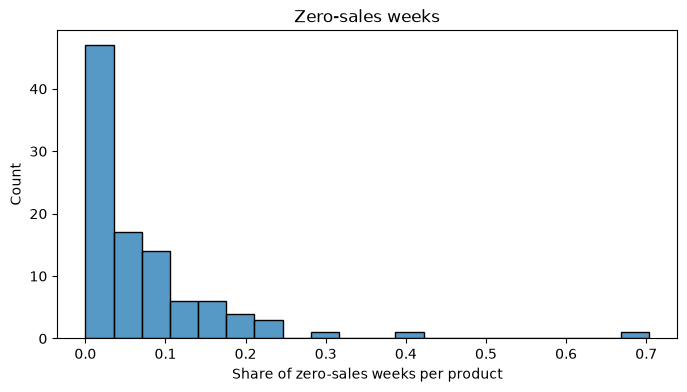

Zero-sales product-weeks :  1007  out of  14500


count    100.000
mean       0.069
std        0.100
min        0.000
25%        0.000
50%        0.041
75%        0.097
max        0.703
Name: sales, dtype: float64

In [15]:
## share of zero-sales weeks per product
zero_share = data.groupby('item_id')['sales'].apply(lambda s: (s == 0).mean())   # share of zero-sales weeks per product

plt.figure(figsize=(8,4))                   # Set Canvas size
sns.histplot(x=zero_share, bins=20)
plt.xlabel("Share of zero-sales weeks per product")
plt.title("Zero-sales weeks")
plt.show()

print("Zero-sales product-weeks : ", (data['sales'] == 0).sum(), " out of ", data.shape[0])
zero_share.describe().round(3)

### Insights :-
- **1,007** of **14,500** product-weeks (**6.9 %**) have zero sales.
- At least **25 %** of the products never had a zero week, and the median product has zero sales in **4.1 %** of its weeks.
- One product has zero sales in **70.3 %** of the weeks in this period.
- A zero week can be low demand or an empty shelf, the data does not tell which.

## ( ii ) . Bi-Variate Analysis :-

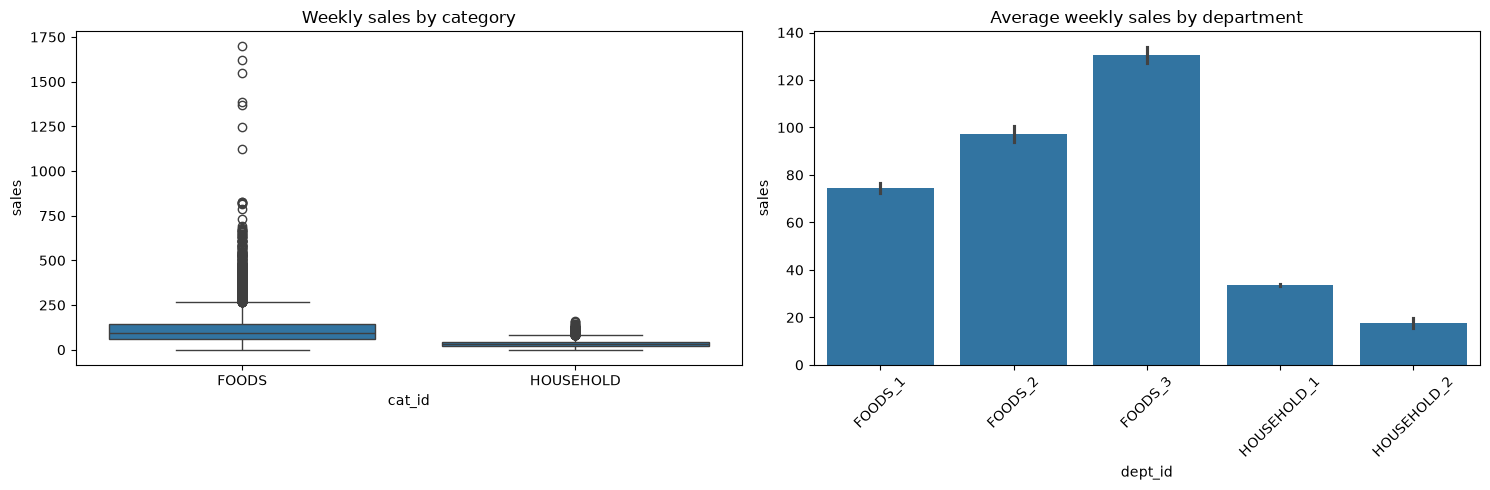

,mean,median,max
dept_id,,,
FOODS_1,74.5,73.0,247
FOODS_2,97.2,88.0,302
FOODS_3,130.4,103.0,1697
HOUSEHOLD_1,33.7,31.0,160
HOUSEHOLD_2,17.8,18.0,49


In [16]:
## weekly sales by category and by department
plt.figure(figsize=(15,5))                  # Set Canvas size
plt.subplot(1,2,1)
sns.boxplot(x='cat_id', y='sales', data=data)
plt.title("Weekly sales by category")
plt.subplot(1,2,2)
sns.barplot(x='dept_id', y='sales', data=data, order=sorted(data['dept_id'].unique()))
plt.title("Average weekly sales by department")
plt.xticks(rotation=45)
plt.tight_layout()                          # to avoid overlapping of plots
plt.show()

data.groupby('dept_id')['sales'].agg(['mean', 'median', 'max']).round(1)

### Insights :-
- FOODS_3 has the biggest weekly sales (mean **130.4**, median **103**) and the biggest week (**1,697**).
- HOUSEHOLD_2 sells the least (mean **17.8**).
- FOODS weeks are both higher and more spread out than HOUSEHOLD weeks, so the products are on very different scales.

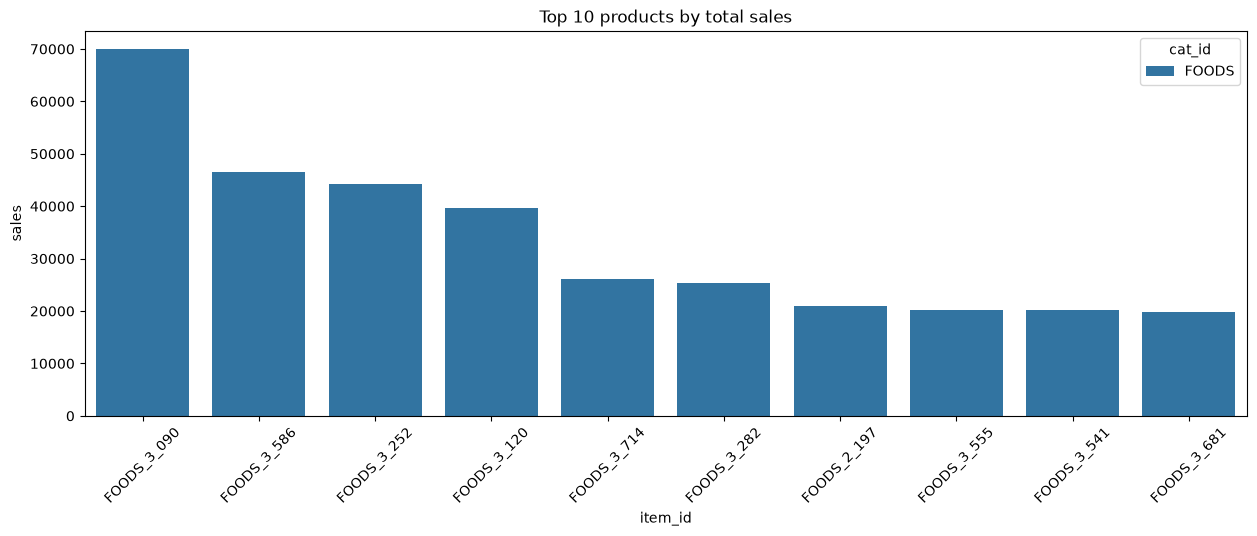

Products making 50 % of total sales :  23


,item_id,cat_id,sales,cum_share
0,FOODS_3_090,FOODS,69959,0.063197
1,FOODS_3_586,FOODS,46450,0.105158
2,FOODS_3_252,FOODS,44329,0.145202
3,FOODS_3_120,FOODS,39711,0.181075
4,FOODS_3_714,FOODS,26134,0.204683
5,FOODS_3_282,FOODS,25353,0.227586
6,FOODS_2_197,FOODS,20869,0.246438
7,FOODS_3_555,FOODS,20230,0.264713
8,FOODS_3_541,FOODS,20111,0.282880
9,FOODS_3_681,FOODS,19851,0.300812


In [17]:
## top 10 products and how many products make half of all sales
top = data.groupby(['item_id', 'cat_id'])['sales'].sum().sort_values(ascending=False).reset_index()   # total sales per product
top['cum_share'] = top['sales'].cumsum() / top['sales'].sum()              # running share of total sales

plt.figure(figsize=(15,5))                  # Set Canvas size
sns.barplot(x='item_id', y='sales', hue='cat_id', data=top.head(10))
plt.title("Top 10 products by total sales")
plt.xticks(rotation=45)
plt.show()

print("Products making 50 % of total sales : ", (top['cum_share'] <= 0.5).sum() + 1)
top.head(10)

### Insights :-
- Only **23** of the 100 products make **50 %** of the total sales.
- The top product **FOODS_3_090** alone makes **6.3 %** of all sales.
- All top 10 products are FOODS, and **9** of them are from FOODS_3.

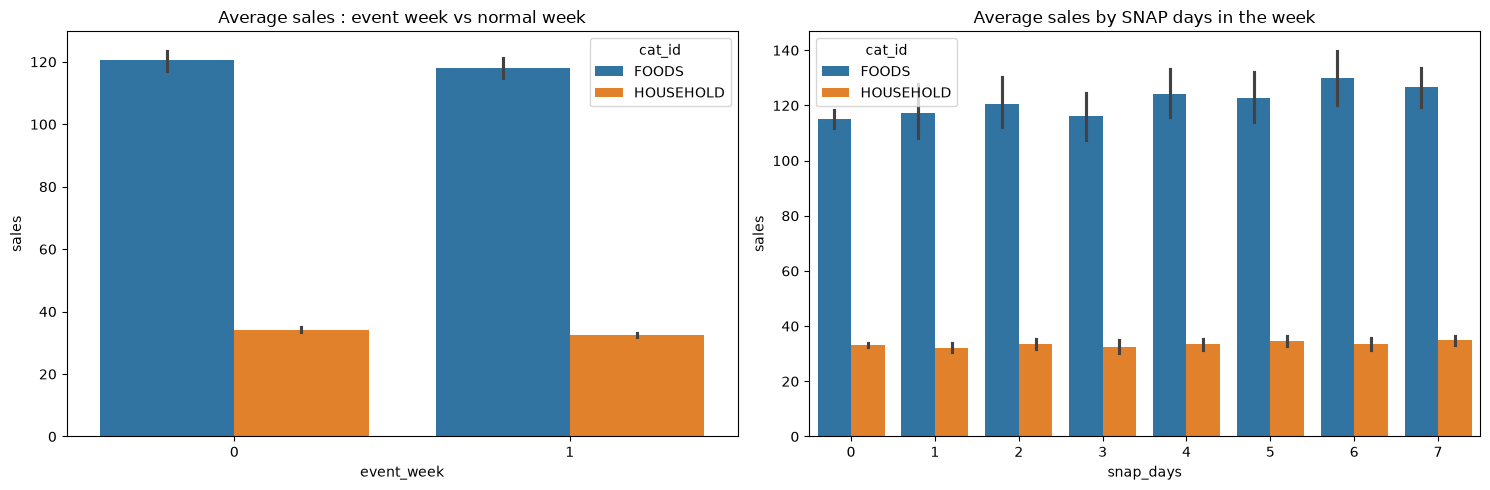

Median ratio of event-week to normal-week sales :  0.97


cat_id,FOODS,HOUSEHOLD
snap_days,,
0,115.24,33.16
1,117.28,32.12
2,120.58,33.43
3,116.22,32.56
4,124.16,33.36
5,122.64,34.44
6,130.12,33.64
7,126.55,34.84


In [18]:
## sales in event weeks and by number of SNAP days
data['event_week'] = (data['event_days'] > 0).astype(int)                      # 1 if the week has any event

plt.figure(figsize=(15,5))                  # Set Canvas size
plt.subplot(1,2,1)
sns.barplot(x='event_week', y='sales', hue='cat_id', data=data)
plt.title("Average sales : event week vs normal week")
plt.subplot(1,2,2)
sns.barplot(x='snap_days', y='sales', hue='cat_id', data=data)
plt.title("Average sales by SNAP days in the week")
plt.tight_layout()                          # to avoid overlapping of plots
plt.show()

## ratio of event-week sales to normal-week sales for each product
ratio = data.groupby(['item_id', 'event_week'])['sales'].mean().unstack()
print("Median ratio of event-week to normal-week sales : ", round((ratio[1] / ratio[0]).median(), 3))
data.groupby(['snap_days', 'cat_id'])['sales'].mean().unstack().round(2)

### Insights :-
- For a typical product, event weeks sell about the same as normal weeks : the median ratio is **0.97**.
- SNAP days matter for **FOODS** : average sales go from **115.24** units with 0 SNAP days to **126.55 to 130.12** with 6 or 7 SNAP days.
- HOUSEHOLD sales stay flat at about **32 to 35** units whatever the SNAP days. This makes sense, because SNAP benefits are for food.

Prices are very different between products, so one scatter plot of price vs sales mixes products. The relation is checked inside each product : the correlation between its own price and its own sales.

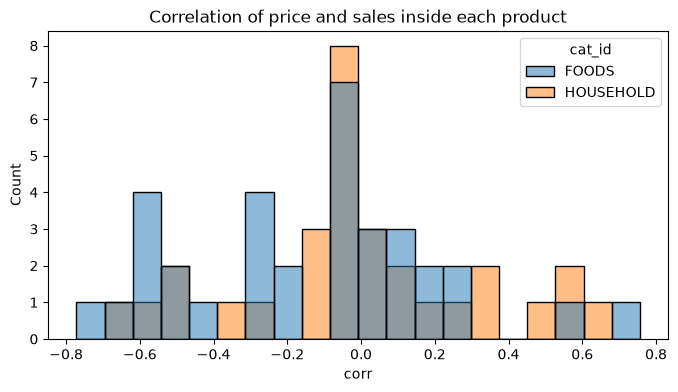

Products with a price change :  64


,count,mean,std,min,25%,50%,75%,max
cat_id,,,,,,,,
FOODS,34.0,-0.128,0.346,-0.772,-0.372,-0.066,0.085,0.756
HOUSEHOLD,30.0,-0.000,0.331,-0.687,-0.099,-0.044,0.179,0.641


In [19]:
## correlation of price and sales inside each product
price_corr = data.dropna(subset=['price']).groupby(['item_id', 'cat_id']).apply(
    lambda g: g['price'].corr(g['sales']) if g['price'].nunique() > 1 else np.nan).rename('corr').reset_index()

plt.figure(figsize=(8,4))                   # Set Canvas size
sns.histplot(x='corr', hue='cat_id', data=price_corr, bins=20)
plt.title("Correlation of price and sales inside each product")
plt.show()

print("Products with a price change : ", price_corr['corr'].notnull().sum())
price_corr.groupby('cat_id')['corr'].describe().round(3)

### Insights :-
- **64** of the 100 products changed price in this period.
- The median correlation between a product's price and its sales is close to zero : **-0.066** for FOODS and **-0.044** for HOUSEHOLD.
- The correlations spread from **-0.77** to **0.76**, so the price effect is different for each product and there is no common pattern.

## ( iii ) . Multivariate Analysis :-

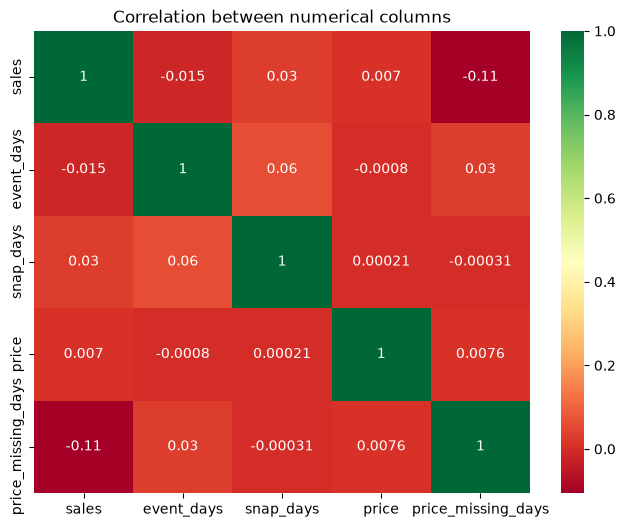

In [20]:
## correlation between the number columns
plt.figure(figsize=(8,6))                   # Set Canvas size
sns.heatmap(data_num.corr(), annot=True, cmap='RdYlGn')
plt.title("Correlation between numerical columns")
plt.show()

### Insights :-
- All correlations between the number columns are close to **0** : the largest is **-0.11** (`sales` and `price_missing_days`).
- So across all products together, events, SNAP days and price explain very little of the weekly sales. Sales depend mostly on the product itself and on its own past.

# 7 . Time Series Analysis :-

Each product is a **time series** : its weekly sales in date order. A forecast uses the past of the series, so we check :
- **trend :** do sales go up or down over the years ?
- **seasonality :** is there a pattern that repeats every year ?
- **stationarity :** does the series keep a stable average, or does it drift ?
- **autocorrelation :** how much does a week depend on the weeks before it ?

Only the weeks up to **18 Oct 2015** are used, as in the rest of this notebook.

## ( i ) . Trend :-

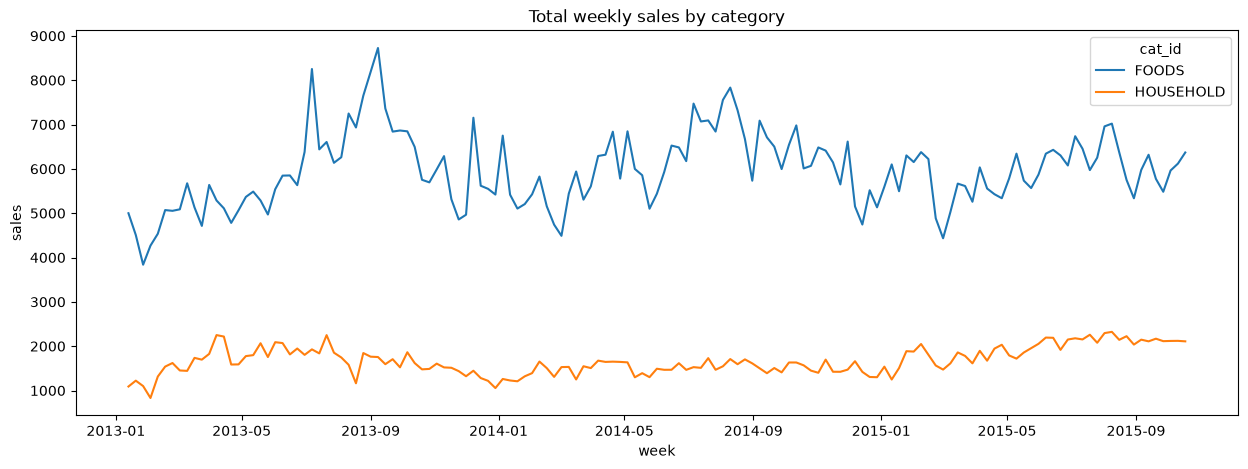

cat_id,FOODS,HOUSEHOLD
week,,
2013,5854.0,1628.0
2014,6102.0,1492.0
2015,5923.0,1947.0


In [21]:
## total weekly sales of each category over time
weekly_cat = data.groupby(['week', 'cat_id'])['sales'].sum().reset_index()      # total weekly sales per category

plt.figure(figsize=(15,5))                  # Set Canvas size
sns.lineplot(x='week', y='sales', hue='cat_id', data=weekly_cat)
plt.title("Total weekly sales by category")
plt.show()

weekly_cat.groupby([weekly_cat['week'].dt.year, 'cat_id'])['sales'].mean().unstack().round(0)   # average weekly sales per year

### Insights :-
- FOODS sells about **3 to 4 times** more than HOUSEHOLD : around **5,900 to 6,100** units per week against **1,500 to 1,950**.
- FOODS has a clear peak in summer every year, the highest in **2013**.
- HOUSEHOLD grows during **2015** (average **1,947** units per week against **1,492** in 2014). The 2015 figure covers only January to October.

## ( ii ) . Seasonality :-

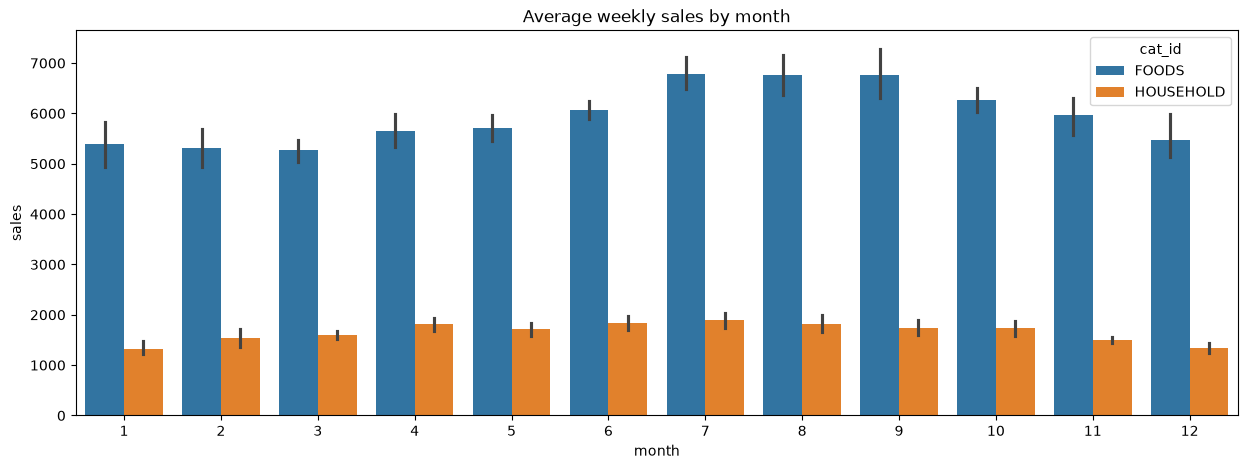

cat_id,FOODS,HOUSEHOLD
month,,
1,5392.0,1328.0
2,5309.0,1538.0
3,5268.0,1590.0
4,5652.0,1817.0
5,5708.0,1723.0
6,6068.0,1834.0
7,6777.0,1897.0
8,6760.0,1823.0
9,6756.0,1745.0


In [22]:
## average weekly sales of each category by month
weekly_cat['month'] = weekly_cat['week'].dt.month                               # month of the week

plt.figure(figsize=(15,5))                  # Set Canvas size
sns.barplot(x='month', y='sales', hue='cat_id', data=weekly_cat)
plt.title("Average weekly sales by month")
plt.show()

weekly_cat.groupby(['month', 'cat_id'])['sales'].mean().unstack().round(0)

### Insights :-
- FOODS sells most in **July to September** (about **6,760** units per week) and least in **March** (**5,268**).
- HOUSEHOLD is highest in **July** (**1,897**) and lowest in **January** (**1,328**) and **December** (**1,334**).
- So there is a yearly pattern at the category level.

## ( iii ) . Decomposition (STL) :-

STL splits a series into three parts that add up to the series :
- **trend :** the slow movement over the years
- **seasonal :** the pattern that repeats every **52** weeks (one year)
- **residual :** what is left, the week-to-week noise

It is shown first on the total sales of the 100 products, then on one product.

The data has less than 3 years (**145** weeks), so each week of the year appears only 2 or 3 times. With its default settings STL would copy the week-to-week noise into the yearly pattern. So the yearly pattern is set to the **average of the same week across the years** (`seasonal_deg=0` with a wide `seasonal` window).

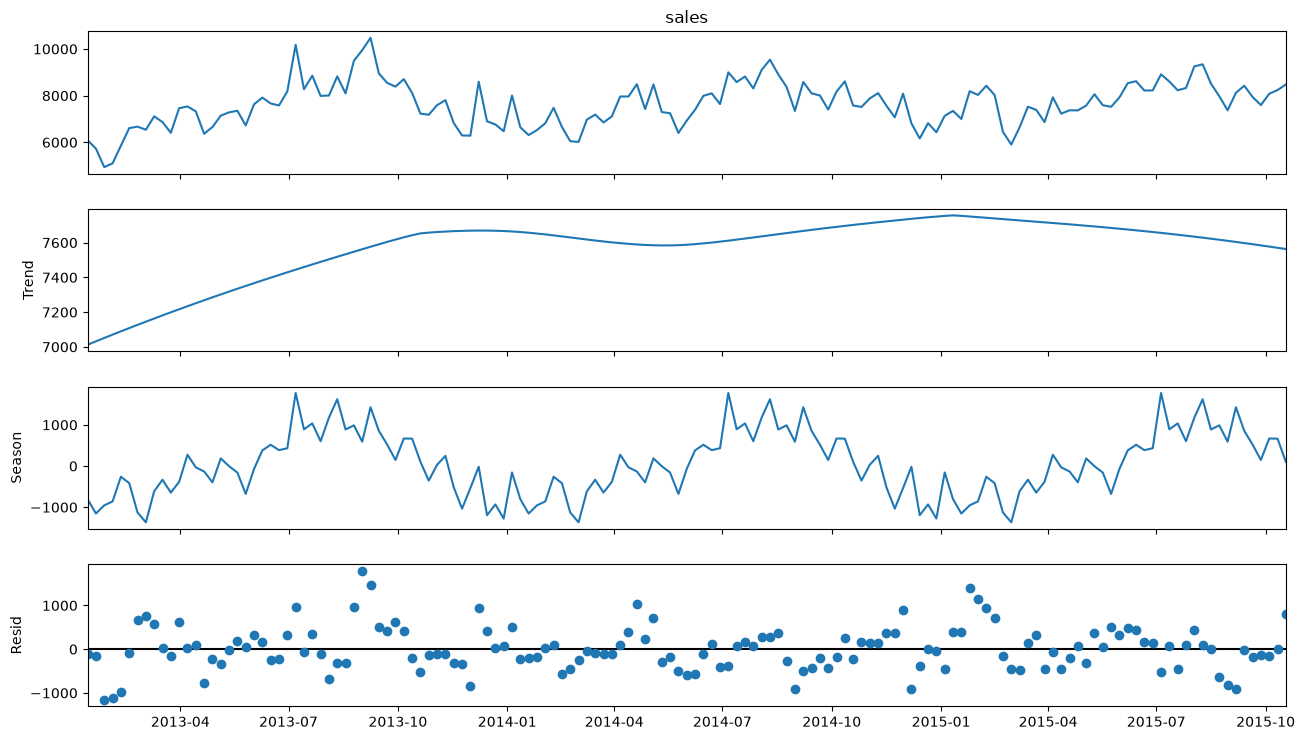

In [23]:
## trend, yearly pattern and residual of the total weekly sales
from statsmodels.tsa.seasonal import STL                                  # import STL decomposition

total = data.groupby('week')['sales'].sum()                               # total weekly sales of the 100 products
stl_total = STL(total, period=52, seasonal=101, seasonal_deg=0).fit()     # 52 weeks = one year

fig = stl_total.plot()
fig.set_size_inches(15, 8)                                                # Set Canvas size
plt.show()

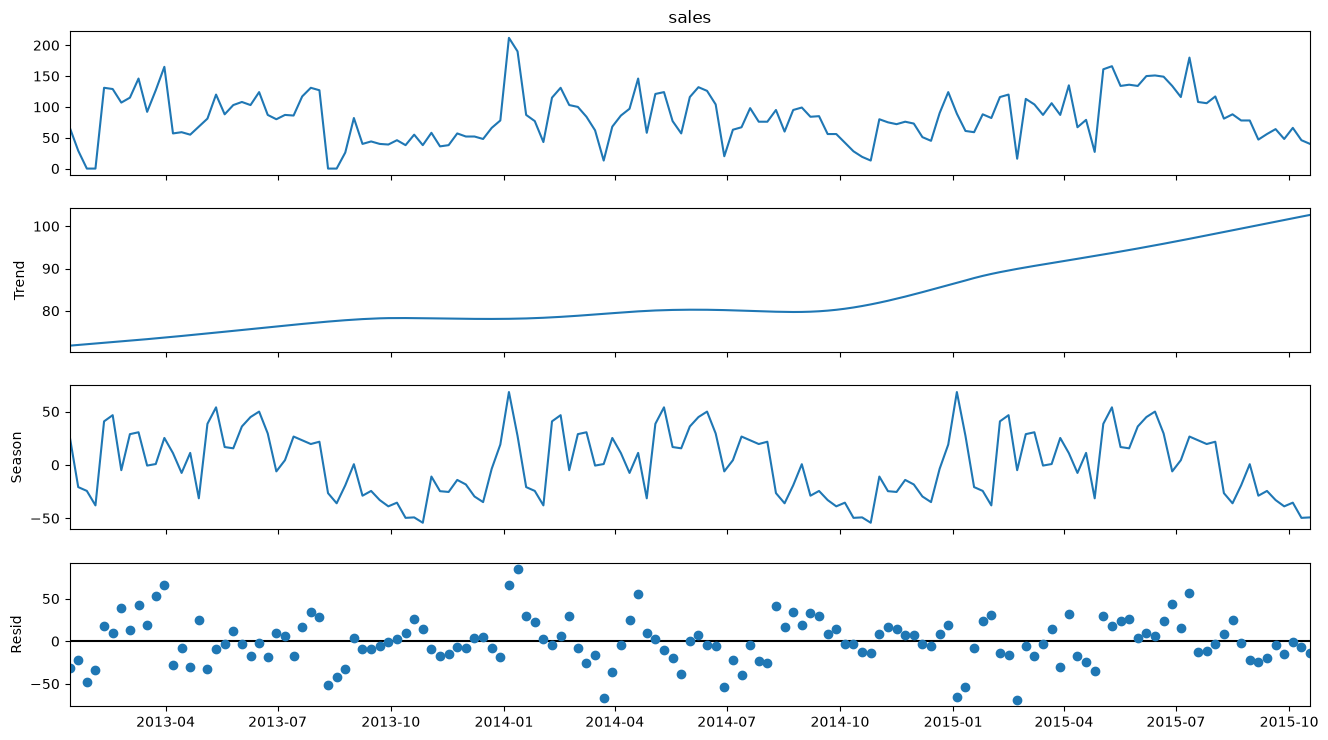

In [24]:
## the same split for one product
one = data[data['item_id'] == 'FOODS_1_004'].set_index('week')['sales']   # weekly sales of one product
stl_one = STL(one, period=52, seasonal=101, seasonal_deg=0).fit()

fig = stl_one.plot()
fig.set_size_inches(15, 8)                                                # Set Canvas size
plt.show()

The **strength** of the trend and of the yearly pattern says how much of a series they explain : **0** means none, **1** means all of it. It is worked out for the total and for every product.

In [25]:
## strength of the trend and of the yearly pattern, for the total and for every product
def strength(res):
    trend = max(0, 1 - res.resid.var() / (res.trend + res.resid).var())
    season = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
    return trend, season

rows = [('Total sales', *strength(stl_total))]
for i, g in data.groupby('item_id'):                                      # one STL per product
    rows.append((i, *strength(STL(g.set_index('week')['sales'], period=52, seasonal=101, seasonal_deg=0).fit())))
strengths = pd.DataFrame(rows, columns=['series', 'trend_strength', 'seasonal_strength'])

print("Total sales : ", strengths.iloc[0, 1:].round(3).to_dict())
strengths.iloc[1:].describe().round(3)                                    # the 100 products

Total sales :  {'trend_strength': 0.163, 'seasonal_strength': 0.701}


,trend_strength,seasonal_strength
count,100.000,100.000
mean,0.323,0.462
std,0.192,0.109
min,0.000,0.263
25%,0.165,0.389
50%,0.290,0.440
75%,0.462,0.530
max,0.786,0.807


### Insights :-
- **Total sales** have a clear yearly pattern that repeats every year : high from **July to September**, low around **January**. Its seasonal strength is **0.701**.
- The trend of the total is small (strength **0.163**) : it moves only between about **7,000** and **7,700** units a week.
- **FOODS_1_004** has a rising trend, from about **72** to **103** units a week, and a yearly peak in early **January**.
- For single products the yearly pattern is weaker : median seasonal strength **0.440** (middle half **0.389** to **0.530**) and median trend strength **0.290**. The noise of a single product hides much of the pattern.
- With less than 3 years, each week of the year is estimated from only 2 or 3 values, so the product-level seasonal strength is a rough estimate. The autocorrelation at 52 weeks below is low (**0.104**).

## ( iv ) . Stationarity Test (ADF) :-

A **stationary** series keeps the same average and spread over time. Many statistical models (like ARIMA) need it, and a series that drifts is made stationary by **differencing** : using the change from the week before instead of the sales.

The **ADF test** checks this. Its starting assumption is that the series is **not** stationary. A **p-value below 0.05** rejects that, so the series is taken as stationary.

In [26]:
## ADF test on the total and on every product, before and after differencing
from statsmodels.tsa.stattools import adfuller                            # import ADF test

adf = data.groupby('item_id')['sales'].apply(lambda s: adfuller(s)[1]).rename('p_value').to_frame()
adf['p_value_diff'] = data.groupby('item_id')['sales'].apply(lambda s: adfuller(s.diff().dropna())[1])

print("Total sales p-value           : ", round(adfuller(total)[1], 4))
print("Stationary products           : ", (adf['p_value'] < 0.05).sum(), "of", len(adf))
print("Stationary after differencing : ", (adf['p_value_diff'] < 0.05).sum(), "of", len(adf))
adf[adf['p_value'] >= 0.05].round(4)                                      # products that are not stationary

Total sales p-value           :  0.0397
Stationary products           :  66 of 100
Stationary after differencing :  100 of 100


,p_value,p_value_diff
item_id,,
FOODS_1_018,0.0884,0.0000
FOODS_2_019,0.0604,0.0000
FOODS_3_064,0.4361,0.0000
FOODS_3_080,0.1971,0.0003
FOODS_3_202,0.3045,0.0000
FOODS_3_282,0.1270,0.0000
FOODS_3_377,0.0546,0.0000
FOODS_3_491,0.2085,0.0000
FOODS_3_499,0.0685,0.0001


### Insights :-
- The total sales are stationary, just : p-value **0.0397**.
- **66** of the 100 products are stationary as they are. The other **34** (**20** HOUSEHOLD and **14** FOODS) drift, with p-values from **0.0508** to **0.7619**.
- **11** of those 34 are only just above the limit (p-value below **0.1**).
- After one differencing (the change from the week before) all **100** products are stationary. For the 34 drifting products the p-value drops to **0.0007** or lower.
- So a statistical model like ARIMA needs differencing (**d = 1**) for the 34 drifting products and none (**d = 0**) for the other 66.

## ( v ) . Autocorrelation :-

Sales of a product depend on its own earlier weeks. The autocorrelation shows how strongly sales are related to sales **k** weeks before, for each product.

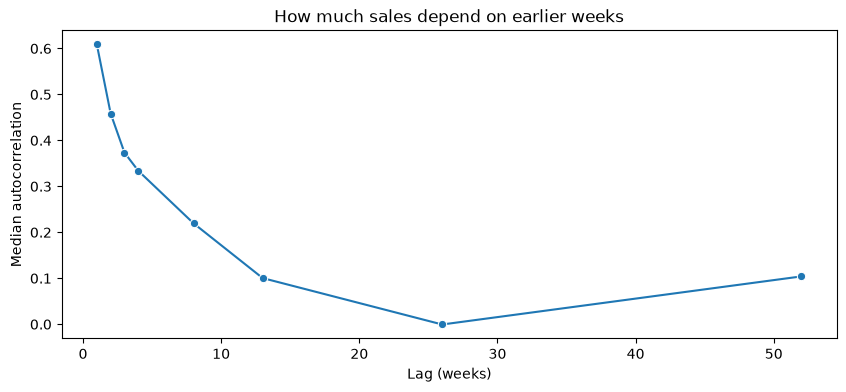

1     0.609
2     0.458
3     0.373
4     0.334
8     0.220
13    0.100
26   -0.001
52    0.104
dtype: float64

In [27]:
## how strongly sales depend on the weeks before
lags = [1, 2, 3, 4, 8, 13, 26, 52]          # weeks back
acf = pd.DataFrame({i: data.groupby('item_id')['sales'].apply(lambda s: s.autocorr(i)) for i in lags})   # autocorrelation per product

plt.figure(figsize=(10,4))                  # Set Canvas size
sns.lineplot(x=lags, y=acf.median().values, marker='o')
plt.xlabel("Lag (weeks)")
plt.ylabel("Median autocorrelation")
plt.title("How much sales depend on earlier weeks")
plt.show()

acf.median().round(3)

### Insights :-
- Sales are strongly related to the week before : median autocorrelation **0.609** at lag 1.
- The relation gets weaker with distance : **0.334** at 4 weeks, **0.100** at 13 weeks and about **0** at 26 weeks.
- At **52** weeks it is only **0.104**, so for a single product the same week last year says little.

The **ACF** shows the correlation with each earlier week. The **PACF** shows the same, but without the part already explained by the weeks in between. Bars outside the blue band are significant. They are shown for a medium product (**FOODS_1_004**) and the biggest one (**FOODS_3_090**).

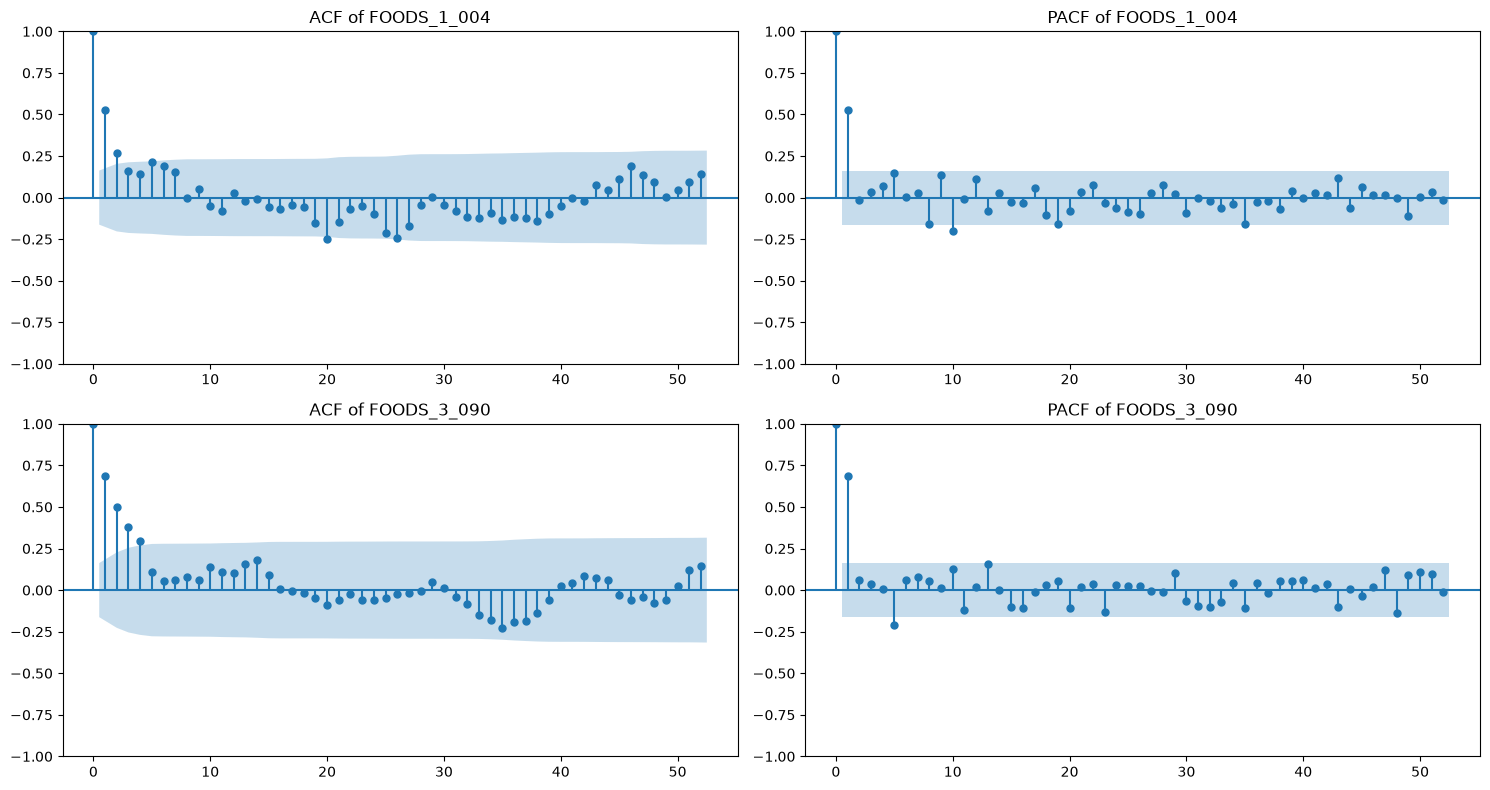

In [28]:
## ACF and PACF of two products, up to 52 weeks back
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf             # import ACF and PACF plots

fig, ax = plt.subplots(2, 2, figsize=(15,8))                              # Set Canvas size
for row, i in enumerate(['FOODS_1_004', 'FOODS_3_090']):
    s = data[data['item_id'] == i]['sales'].values
    plot_acf(s, lags=52, ax=ax[row, 0], title="ACF of " + i)
    plot_pacf(s, lags=52, ax=ax[row, 1], title="PACF of " + i, method='ywm')
plt.tight_layout()                                                        # to avoid overlapping of plots
plt.show()

In [29]:
## first 6 values of the ACF and PACF, and the significance limit
from statsmodels.tsa.stattools import acf, pacf                           # import ACF and PACF values

values = {}
for i in ['FOODS_1_004', 'FOODS_3_090']:
    s = data[data['item_id'] == i]['sales'].values
    values['ACF ' + i] = acf(s, nlags=6)[1:]
    values['PACF ' + i] = pacf(s, nlags=6, method='ywm')[1:]

print("Significance limit : ", round(1.96 / np.sqrt(145), 3))
pd.DataFrame(values, index=range(1, 7)).round(3)

Significance limit :  0.163


,ACF FOODS_1_004,PACF FOODS_1_004,ACF FOODS_3_090,PACF FOODS_3_090
1,0.529,0.529,0.686,0.686
2,0.269,-0.015,0.502,0.058
3,0.160,0.032,0.382,0.035
4,0.143,0.068,0.293,0.009
5,0.214,0.150,0.111,-0.212
6,0.189,0.006,0.057,0.062


### Insights :-
- The significance limit is **0.163** : values beyond it are real, not chance.
- **FOODS_1_004** : ACF **0.529** at 1 week, **0.269** at 2 weeks, then small (**0.143** to **0.214** for weeks 3 to 6). The PACF has one clear bar at 1 week (**0.529**), the next ones are close to **0**.
- **FOODS_3_090** : the ACF fades slowly (**0.686, 0.502, 0.382, 0.293**), but the PACF again has one clear bar at 1 week (**0.686**). Only week 5 is beyond the limit (**-0.212**).
- One PACF bar with a slowly fading ACF is the pattern of an **AR(1)** series : sales depend directly on last week, and the older weeks act mostly through it. So a small ARIMA order (**p = 1**) is the starting point.
- Neither product has a bar at **52** weeks outside the band, which matches the weak link to the same week last year.

# ----- CONCLUSION -----

**Findings :**
- The weekly data is clean : no duplicates, every product has all **145** weeks, and the only missing prices are weeks before a product's first price.
- Weekly sales are right skewed (skew **4.32**), **6.9 %** of the product-weeks are zero, and the products sell on very different scales. So an error measure that is scaled per product, like RMSSE, is more suitable than MAPE.
- The last few weeks of a product are the strongest signal (autocorrelation **0.609** at lag 1, **0.334** at lag 4).
- There is a yearly pattern at the category level (FOODS high in **July to September**, HOUSEHOLD high in **July**), but it is weak for single products (**0.104** at lag 52).
- SNAP days raise FOODS sales (**115.24** units with 0 SNAP days against **126.55 to 130.12** with 6 or 7), events change little for a typical product (ratio **0.97**), and the price effect is different for each product.
- The **13** sales peaks are real recorded sales, mostly in event weeks.
- **Time series analysis :** the yearly pattern is clear in the total sales (seasonal strength **0.701**) but weaker for single products (median **0.440**), and the trends are small. **66** products are stationary, the other **34** become stationary after one differencing. The ACF and PACF point to an **AR(1)** pattern.

**Data preprocessing needed :**
- **Outliers :** keep the **13** peaks as they are. They are real sales, and for stock planning the big weeks matter most. Tree models are not thrown off by a few large values.
- **Zero-sales weeks :** keep them as **0**. The data cannot tell low demand from an empty shelf, so replacing them would invent sales.
- **Missing prices :** leave the **190** empty prices empty. XGBoost, LightGBM and recent Random Forest versions handle empty values. Never fill them with a later price, that would use the future.
- **Skewed sales :** no change needed for tree models. A log transform of sales can be tried only as an experiment, judged on the development weeks.
- **Different product scales :** handled by the per-product error measure and by features relative to the product's own level (rolling averages). No min-max scaling is needed for tree models.
- **Category and department :** turn the text into numbers (one 0/1 column per value).

**Features to build :**
- **sales of the last 1 to 4 weeks (lags) :** the strongest signal
- **rolling averages of the last 4, 8 and 13 weeks :** smooth the weekly noise and give each product its own normal level
- **month and week of the year of the forecast week :** the yearly pattern of each category
- **SNAP days of the forecast week :** they lift FOODS sales
- **event days of the forecast week :** weak overall, but most peaks are in event weeks, so the model can decide
- **price and price change (against last week and the recent average) :** the effect differs per product, so the models are trained with and without these and compared
- **category and department :** very different sales levels
- **sales of the same week last year (lag 52) :** weak for single products, optional

**For the statistical model :**
- start from a small ARIMA order, **p = 1**, as the PACF shows
- differencing per product from the ADF test : **d = 1** for the 34 drifting products, **d = 0** for the other 66
- the yearly pattern as smooth **Fourier terms** (sine and cosine waves over 52 weeks) instead of a seasonal ARIMA, because less than 3 years is too short for a 52-week seasonal part

**Rules for the split and the features :**
- the data is split **by time** first (forecast dates), then the features are built for each forecast date
- a feature for a forecast made on Sunday **t** uses only the weeks up to **t**. The calendar of the forecast week (month, SNAP days, event days) is allowed, because it is known in advance
- rolling averages are built from past weeks only (shift first, then average)
- anything learned from the data (encodings, fill values) is learned from the training weeks only
- no random train / test split, no outlier capping on all the data, no filling with later values